# ¿Es razonable el precio de esta vivienda? Viviendas en venta en Madrid capital

Fundamentos de la Ciencia de Datos · Proyecto individual · Entrega 1 (datos y EDA)

**Autor:** Vicente Sánchez Reza

Este cuaderno contiene todo el código de la Entrega 1 y se ejecuta de arriba abajo (Kernel > Restart & Run All). Las figuras se guardan en la carpeta `figuras/` para el informe.

**Preguntas de negocio**
1. ¿Cuánto se desvía (en %) el precio por m² de una vivienda respecto a la mediana de su mismo distrito y tramo de superficie (75 a 100 m²)? Grupos de al menos 5 viviendas.
2. ¿Qué diferencia hay entre la mediana del precio por m² de los distritos céntricos y la de los periféricos, para viviendas de 75 a 100 m²?
3. ¿Qué diferencia de precio por m² hay entre viviendas en planta baja (planta 0 o negativa) y en plantas altas (planta 2 o más), por tramo de superficie?

**Índice**
1. Configuración y funciones
2. Carga de datos
3. Sobre la fuente de datos: estructura y calidad inicial
4. Variables derivadas
5. EDA univariado
6. Problemas de los datos
7. EDA bivariado y multivariado
8. Pregunta 1: desviación respecto a la mediana del distrito
9. Pregunta 2: céntricos frente a periféricos
10. Pregunta 3: plantas bajas frente a plantas altas
11. Sensibilidad: sin duplicados
12. Resumen de resultados

## 1. Configuración y funciones
Importaciones, constantes del análisis y las funciones auxiliares que se usan en el resto del cuaderno.

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")
os.makedirs("figuras", exist_ok=True)

# Parámetros del análisis (definidos en el caso de negocio)
TRAMO_MIN, TRAMO_MAX = 75, 100          # tramo de superficie de las preguntas 1 y 2 (m²)
MIN_GRUPO = 5                           # tamaño mínimo de grupo para calcular una mediana
CENTRICOS = ["Barrio de Salamanca", "Centro", "Chamberí", "Retiro"]
PERIFERICOS = ["Villaverde", "Puente de Vallecas", "Villa de Vallecas"]


def grupo_planta(p):
    """Agrupa la planta: bajo (0 o negativa), entreplanta (0,5), planta 1 y alta (2 o más)."""
    if p <= 0:
        return "bajo (0 o menos)"
    if p < 1:
        return "entreplanta (0,5)"
    if p == 1:
        return "planta 1"
    return "alta (2 o más)"


def tramo_sup(s):
    """Tramo de superficie para la pregunta 3."""
    if s < TRAMO_MIN:
        return "menos de 75 m²"
    if s <= TRAMO_MAX:
        return "75 a 100 m²"
    return "más de 100 m²"


def guardar(nombre):
    """Guarda la figura actual en figuras/ y la muestra."""
    plt.savefig(f"figuras/{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 2. Carga de datos
Se lee el CSV de Fotocasa (Madrid, noviembre de 2024) de la carpeta `data/`. El separador se detecta automáticamente.

In [ ]:
df = pd.read_csv("data/fotocasa_Madrid_datos_finales.csv", sep=None, engine="python")
df.head()

,precio,habitaciones,baños,superficie,distrito,planta,ascensor,calefacción,aire_acondicionado,cluster
0,"350,000.00",1.00,1.00,72.00,Arganzuela,0.00,1,1,0,1
1,"3,750,000.00",3.00,6.00,662.00,Arganzuela,0.00,0,1,1,0
2,"1,300,000.00",4.00,2.00,360.00,Arganzuela,1.00,1,0,1,0
3,"539,000.00",3.00,2.00,105.00,Arganzuela,2.00,1,1,0,1
4,"632,900.00",3.00,2.00,124.00,Arganzuela,1.00,1,1,1,1


## 3. Sobre la fuente de datos: estructura y calidad inicial
Dimensiones, tipos, estadísticos descriptivos, nulos y duplicados.

In [ ]:
print("Dimensiones:", df.shape)
df.info()

Dimensiones: (1636, 10)
<class 'pandas.DataFrame'>
RangeIndex: 1636 entries, 0 to 1635
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   precio              1636 non-null   float64
 1   habitaciones        1636 non-null   float64
 2   baños               1636 non-null   float64
 3   superficie          1636 non-null   float64
 4   distrito            1636 non-null   str    
 5   planta              1636 non-null   float64
 6   ascensor            1636 non-null   int64  
 7   calefacción         1636 non-null   int64  
 8   aire_acondicionado  1636 non-null   int64  
 9   cluster             1636 non-null   int64  
dtypes: float64(5), int64(4), str(1)
memory usage: 127.9 KB


In [ ]:
display(df.describe(include="all").T)
print("Nulos por columna:")
print(df.isna().sum())
print("Filas duplicadas:", df.duplicated().sum())

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
precio,"1,636.00",NaN,NaN,NaN,"749,700.47","811,065.41","112,000.00","255,000.00","445,000.00","895,000.00","4,500,000.00"
habitaciones,"1,636.00",NaN,NaN,NaN,2.77,1.26,1.00,2.00,3.00,3.00,7.00
baños,"1,636.00",NaN,NaN,NaN,1.93,1.11,1.00,1.00,2.00,2.00,6.00
superficie,"1,636.00",NaN,NaN,NaN,128.30,108.54,28.00,66.00,98.00,144.00,720.00
distrito,1636,21,Centro,199,NaN,NaN,NaN,NaN,NaN,NaN,NaN
planta,"1,636.00",NaN,NaN,NaN,1.74,1.99,-2.00,1.00,1.00,1.00,15.00
ascensor,"1,636.00",NaN,NaN,NaN,0.34,0.48,0.00,0.00,0.00,1.00,1.00
calefacción,"1,636.00",NaN,NaN,NaN,0.21,0.41,0.00,0.00,0.00,0.00,1.00
aire_acondicionado,"1,636.00",NaN,NaN,NaN,0.08,0.27,0.00,0.00,0.00,0.00,1.00
cluster,"1,636.00",NaN,NaN,NaN,0.83,0.37,0.00,1.00,1.00,1.00,1.00


Nulos por columna:
precio                0
habitaciones          0
baños                 0
superficie            0
distrito              0
planta                0
ascensor              0
calefacción           0
aire_acondicionado    0
cluster               0
dtype: int64
Filas duplicadas: 38


## 4. Variables derivadas
Se crean el precio por m², el grupo de planta y la marca de anuncios con valores topados (ver sección 6). `habitaciones` y `baños` pasan a entero; `planta` se mantiene decimal porque hay anuncios con planta 0,5.

In [ ]:
for col in ["habitaciones", "baños"]:
    df[col] = df[col].astype(int)

df["precio_m2"] = df["precio"] / df["superficie"]
df["grupo_planta"] = df["planta"].apply(grupo_planta)

# Anuncios con precio o superficie igual al máximo de la columna (valores topados)
df["topado"] = (df["precio"] == df["precio"].max()) | (df["superficie"] == df["superficie"].max())

display(df["precio_m2"].describe())

count    1,636.00
mean     5,545.97
std      3,027.21
min        566.48
25%      3,445.30
50%      4,948.94
75%      6,758.74
max     45,918.37
Name: precio_m2, dtype: float64

## 5. EDA univariado
### 5.1 Variables numéricas continuas: precio, superficie y precio por m²
Histogramas con mediana (rojo) y media (naranja).

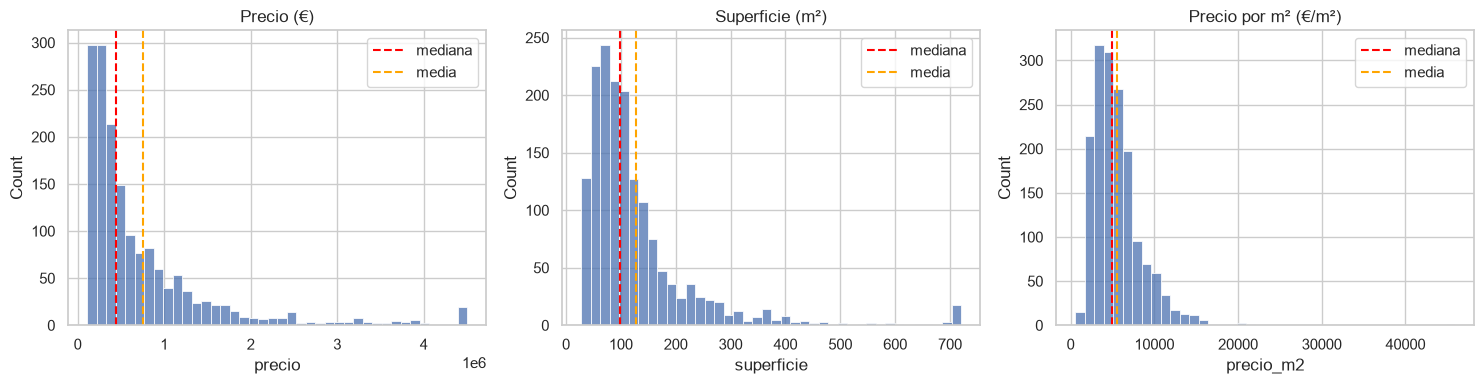

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, col, titulo in zip(ejes, ["precio", "superficie", "precio_m2"],
                            ["Precio (€)", "Superficie (m²)", "Precio por m² (€/m²)"]):
    sns.histplot(df[col], bins=40, ax=eje)
    eje.axvline(df[col].median(), color="red", linestyle="--", label="mediana")
    eje.axvline(df[col].mean(), color="orange", linestyle="--", label="media")
    eje.set_title(titulo)
    eje.legend()
plt.tight_layout()
guardar("01_histogramas")

Diagramas de caja de las mismas tres variables.

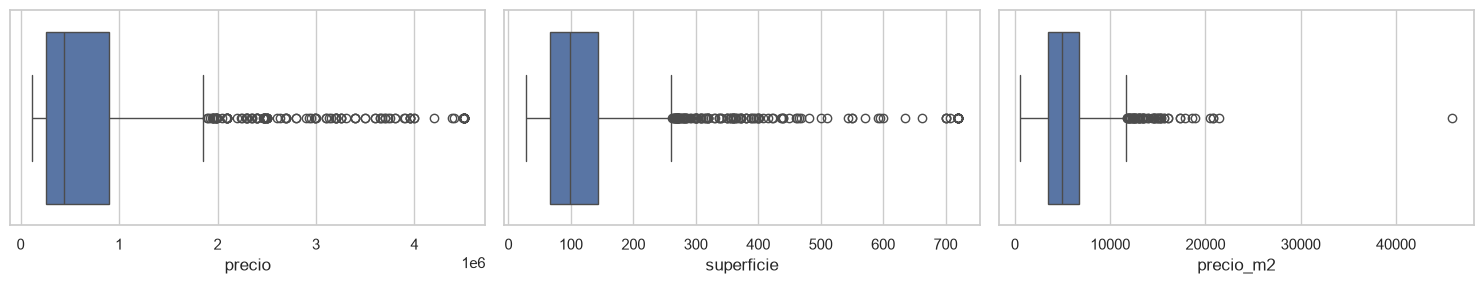

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 3))
for eje, col in zip(ejes, ["precio", "superficie", "precio_m2"]):
    sns.boxplot(x=df[col], ax=eje)
plt.tight_layout()
guardar("02_cajas")

**Interpretación (a completar):** forma de las distribuciones, diferencia entre media y mediana, valores atípicos.

### 5.2 Variables discretas y categóricas: habitaciones, baños, planta y distrito

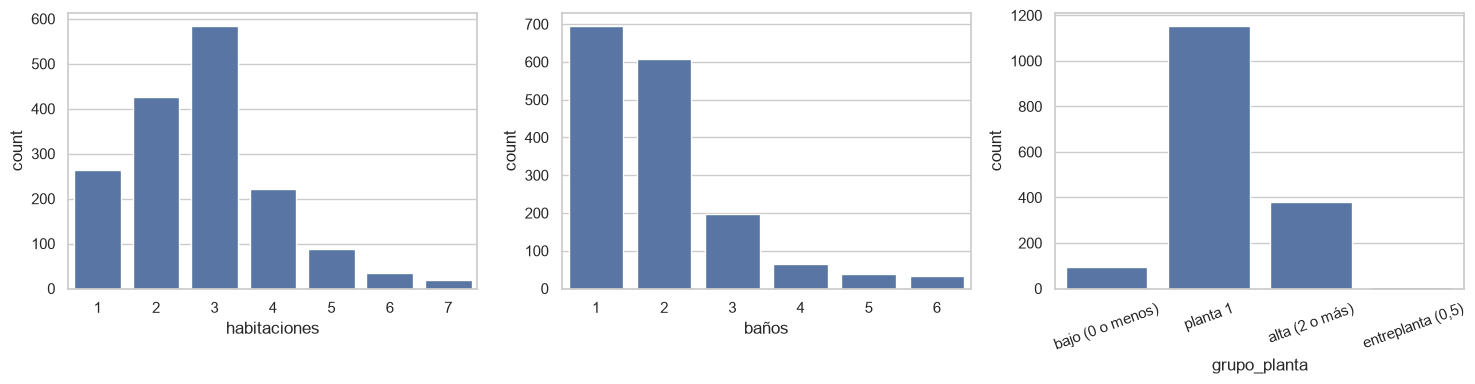

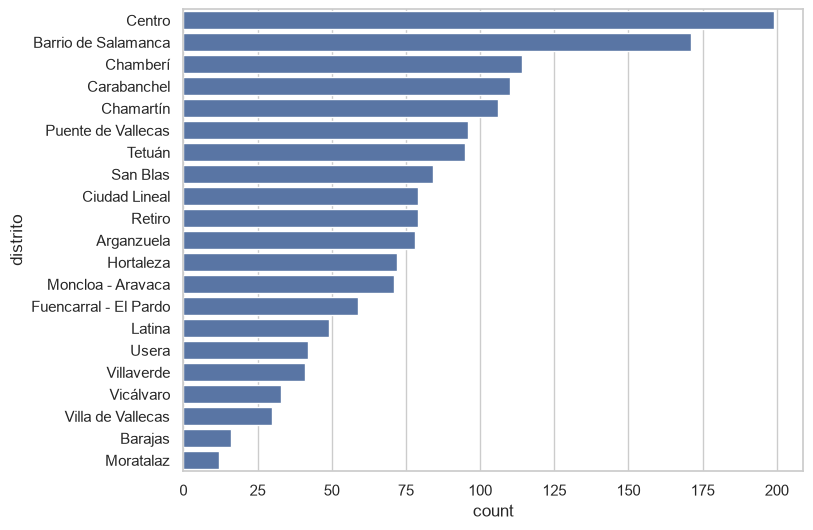

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x="habitaciones", data=df, ax=ejes[0])
sns.countplot(x="baños", data=df, ax=ejes[1])
sns.countplot(x="grupo_planta", data=df, ax=ejes[2])
ejes[2].tick_params(axis="x", rotation=20)
plt.tight_layout()
guardar("03_habitaciones_banos_planta")

plt.figure(figsize=(8, 6))
sns.countplot(y="distrito", data=df, order=df["distrito"].value_counts().index)
guardar("04_distritos")

In [ ]:
print(df["distrito"].value_counts()); print()
print(df["planta"].value_counts().sort_index()); print()
print(df["grupo_planta"].value_counts()); print()
print(df["grupo_planta"].value_counts(normalize=True).round(3))

distrito
Centro                   199
Barrio de Salamanca      171
Chamberí                 114
Carabanchel              110
Chamartín                106
Puente de Vallecas        96
Tetuán                    95
San Blas                  84
Ciudad Lineal             79
Retiro                    79
Arganzuela                78
Hortaleza                 72
Moncloa - Aravaca         71
Fuencarral - El Pardo     59
Latina                    49
Usera                     42
Villaverde                41
Vicálvaro                 33
Villa de Vallecas         30
Barajas                   16
Moratalaz                 12
Name: count, dtype: int64

planta
-2.00       1
-1.00       3
0.00       90
0.50        8
1.00     1153
2.00       94
3.00       86
4.00       55
5.00       38
6.00       47
7.00       19
8.00       19
9.00        6
10.00       7
15.00      10
Name: count, dtype: int64

grupo_planta
planta 1             1153
alta (2 o más)        381
bajo (0 o menos)       94
entreplanta (0,5)   

**Interpretación (a completar):** distritos con más y menos anuncios, concentración en la planta 1, habitaciones y baños más frecuentes.

### 5.3 Variables binarias: ascensor, calefacción, aire acondicionado y cluster

In [ ]:
binarias = ["ascensor", "calefacción", "aire_acondicionado", "cluster"]
display(df[binarias].apply(lambda s: s.value_counts(normalize=True)).round(3).T)

,0,1
ascensor,0.66,0.34
calefacción,0.79,0.21
aire_acondicionado,0.92,0.08
cluster,0.17,0.83


## 6. Problemas de los datos
### 6.1 Duplicados
Filas completamente idénticas (no hay identificador de anuncio, así que no se puede saber si son el mismo anuncio publicado dos veces o dos viviendas iguales).

In [ ]:
print("Filas duplicadas:", df.duplicated().sum())
display(df[df.duplicated(keep=False)].sort_values(["distrito", "precio"]).head(10))

Filas duplicadas: 38


,precio,habitaciones,baños,superficie,distrito,planta,ascensor,calefacción,aire_acondicionado,cluster,precio_m2,grupo_planta,topado
44,"550,000.00",3,2,117.00,Arganzuela,1.00,0,0,0,1,"4,700.85",planta 1,False
57,"550,000.00",3,2,117.00,Arganzuela,1.00,0,0,0,1,"4,700.85",planta 1,False
30,"561,947.00",1,1,117.00,Arganzuela,1.00,0,0,0,1,"4,802.97",planta 1,False
38,"561,947.00",1,1,117.00,Arganzuela,1.00,0,0,0,1,"4,802.97",planta 1,False
191,"290,000.00",1,1,40.00,Barrio de Salamanca,1.00,0,0,0,1,"7,250.00",planta 1,False
192,"290,000.00",1,1,40.00,Barrio de Salamanca,1.00,0,0,0,1,"7,250.00",planta 1,False
205,"675,000.00",2,2,75.00,Barrio de Salamanca,1.00,0,0,0,1,"9,000.00",planta 1,False
223,"675,000.00",2,2,75.00,Barrio de Salamanca,1.00,0,0,0,1,"9,000.00",planta 1,False
193,"750,000.00",2,2,74.00,Barrio de Salamanca,1.00,0,0,0,1,"10,135.14",planta 1,False
194,"750,000.00",2,2,74.00,Barrio de Salamanca,1.00,0,0,0,1,"10,135.14",planta 1,False


### 6.2 Valores topados
El precio máximo (4.500.000 €) y la superficie máxima (720 m²) se repiten en muchos anuncios, lo que sugiere que la fuente los recorta (el precio real sería mayor). Los 9 anuncios que cumplen ambos topes dan un precio por m² artificial de 6.250 €/m².

In [ ]:
tope_precio = df["precio"] == df["precio"].max()
tope_sup = df["superficie"] == df["superficie"].max()
print("Anuncios con el precio máximo:", tope_precio.sum())
print("Anuncios con la superficie máxima:", tope_sup.sum())
print("Coinciden en ambos:", (tope_precio & tope_sup).sum())
print("Anuncios topados:", df["topado"].sum(), f"({df['topado'].mean():.1%})")

cols = ["precio", "superficie", "distrito", "planta", "precio_m2"]
display(df[df["topado"]][cols].sort_values("precio_m2"))

Anuncios con el precio máximo: 17
Anuncios con la superficie máxima: 17
Coinciden en ambos: 9
Anuncios topados: 25 (1.5%)


,precio,superficie,distrito,planta,precio_m2
472,"1,375,000.00",720.00,Centro,1.00,"1,909.72"
898,"2,460,000.00",720.00,Fuencarral - El Pardo,1.00,"3,416.67"
1104,"2,500,000.00",720.00,Moncloa - Aravaca,1.00,"3,472.22"
1083,"2,925,544.00",720.00,Moncloa - Aravaca,1.00,"4,063.26"
899,"3,000,000.00",720.00,Fuencarral - El Pardo,1.00,"4,166.67"
1087,"3,100,000.00",720.00,Moncloa - Aravaca,1.00,"4,305.56"
1084,"3,650,000.00",720.00,Moncloa - Aravaca,1.00,"5,069.44"
1057,"4,200,000.00",720.00,Moncloa - Aravaca,1.00,"5,833.33"
961,"4,500,000.00",720.00,Hortaleza,1.00,"6,250.00"
1085,"4,500,000.00",720.00,Moncloa - Aravaca,1.00,"6,250.00"


Se excluyen los anuncios topados del análisis de las preguntas. El resultado es `df_ok`.

In [ ]:
df_ok = df[~df["topado"]].copy()
print("Filas en df_ok:", len(df_ok), "(de", len(df), ")")

Filas en df_ok: 1611 (de 1636 )


### 6.3 Extremos del precio por m²

In [ ]:
display(df.nlargest(5, "precio_m2")[cols])
display(df.nsmallest(5, "precio_m2")[cols])

,precio,superficie,distrito,planta,precio_m2
960,"4,500,000.00",98.00,Hortaleza,1.00,"45,918.37"
405,"3,130,000.00",146.00,Centro,4.00,"21,438.36"
1066,"2,500,000.00",120.00,Moncloa - Aravaca,1.00,"20,833.33"
1096,"2,500,000.00",120.00,Moncloa - Aravaca,1.00,"20,833.33"
143,"3,950,000.00",193.00,Barrio de Salamanca,6.00,"20,466.32"


,precio,superficie,distrito,planta,precio_m2
1052,"152,950.00",270.00,Latina,1.00,566.48
374,"505,000.00",407.00,Carabanchel,1.00,"1,240.79"
1004,"121,000.00",97.00,Latina,2.00,"1,247.42"
1212,"123,000.00",98.00,Puente de Vallecas,1.00,"1,255.10"
1632,"150,000.00",119.00,Villaverde,1.00,"1,260.50"


### 6.4 Planta con valores raros y grupos pequeños
Hay 8 anuncios con planta 0,5 (se tratan como un grupo aparte) y alrededor del 70 % de los anuncios están en la planta 1, lo que limita la comparación bajos frente a altas. Además, algunos distritos tienen pocas viviendas en el tramo de 75 a 100 m².

In [ ]:
print("Anuncios con planta 0,5:", (df["planta"] == 0.5).sum())
en_tramo = df_ok[df_ok["superficie"].between(TRAMO_MIN, TRAMO_MAX)]
print("Viviendas de 75 a 100 m² (sin topados):", len(en_tramo))
print(en_tramo["distrito"].value_counts())

Anuncios con planta 0,5: 8
Viviendas de 75 a 100 m² (sin topados): 337
distrito
Carabanchel              35
Barrio de Salamanca      32
Centro                   29
Puente de Vallecas       25
Ciudad Lineal            24
Tetuán                   21
Chamartín                20
San Blas                 18
Chamberí                 15
Hortaleza                15
Latina                   15
Arganzuela               13
Retiro                   12
Fuencarral - El Pardo    10
Vicálvaro                10
Villa de Vallecas        10
Usera                     8
Villaverde                8
Moncloa - Aravaca         6
Moratalaz                 6
Barajas                   5
Name: count, dtype: int64


**Otros problemas a comentar en el informe (sin código):** la columna `cluster` no está documentada, no hay nulos (probablemente la fuente ya los imputó o eliminó), son precios de oferta y no de venta, y no hay distancia al centro ni barrio.

## 7. EDA bivariado y multivariado
Se usa `df_ok` (sin valores topados). Precio por m² frente a distrito, superficie, planta y características, y correlaciones.

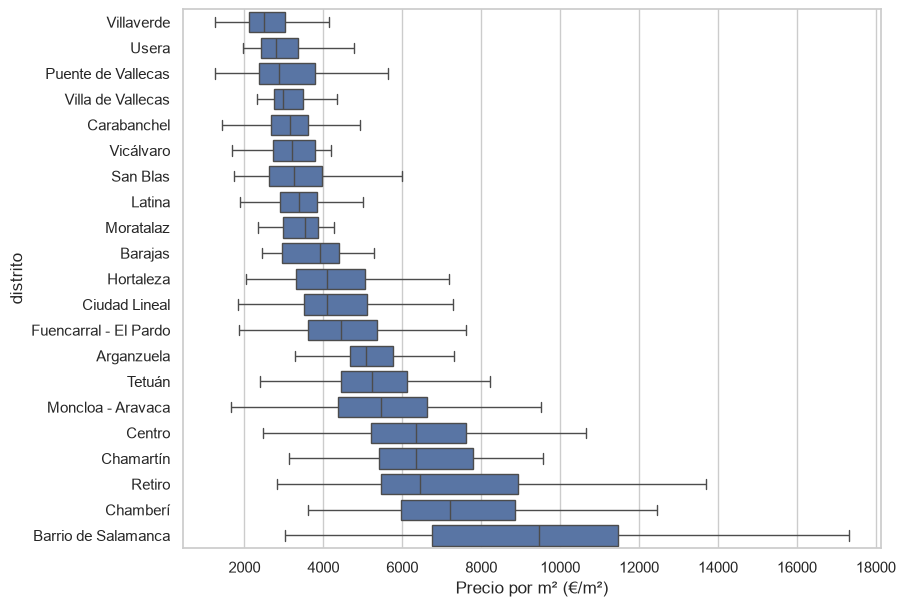

In [ ]:
orden = df_ok.groupby("distrito")["precio_m2"].median().sort_values().index
plt.figure(figsize=(9, 7))
sns.boxplot(y="distrito", x="precio_m2", data=df_ok, order=orden, showfliers=False)
plt.xlabel("Precio por m² (€/m²)")
guardar("05_precio_m2_por_distrito")

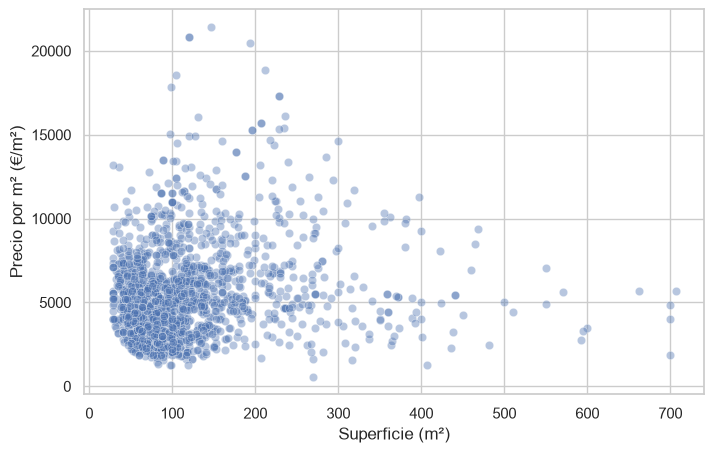

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="superficie", y="precio_m2", data=df_ok, alpha=0.4)
plt.xlabel("Superficie (m²)")
plt.ylabel("Precio por m² (€/m²)")
guardar("06_superficie_vs_precio_m2")

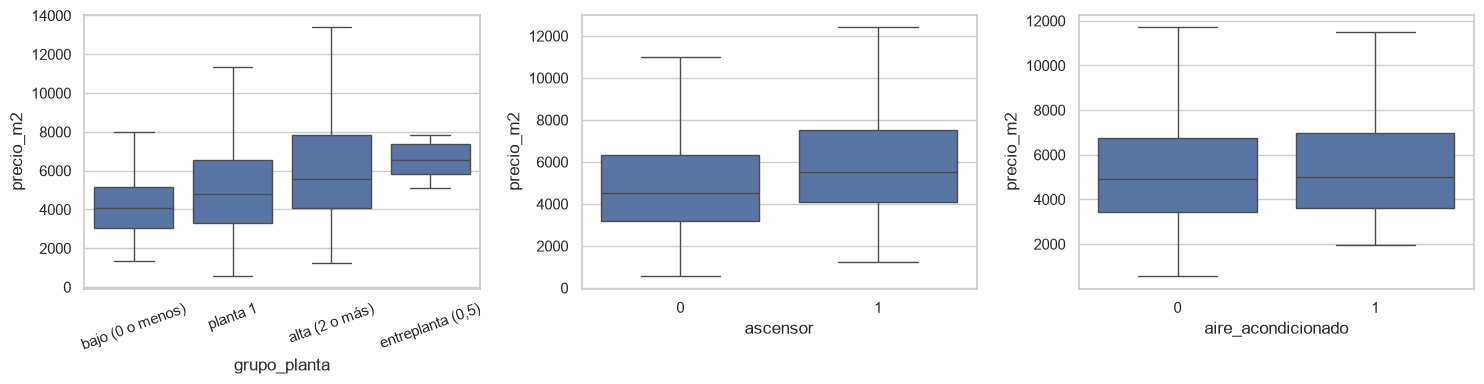

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x="grupo_planta", y="precio_m2", data=df_ok, showfliers=False, ax=ejes[0])
ejes[0].tick_params(axis="x", rotation=20)
sns.boxplot(x="ascensor", y="precio_m2", data=df_ok, showfliers=False, ax=ejes[1])
sns.boxplot(x="aire_acondicionado", y="precio_m2", data=df_ok, showfliers=False, ax=ejes[2])
plt.tight_layout()
guardar("07_precio_m2_planta_y_caracteristicas")

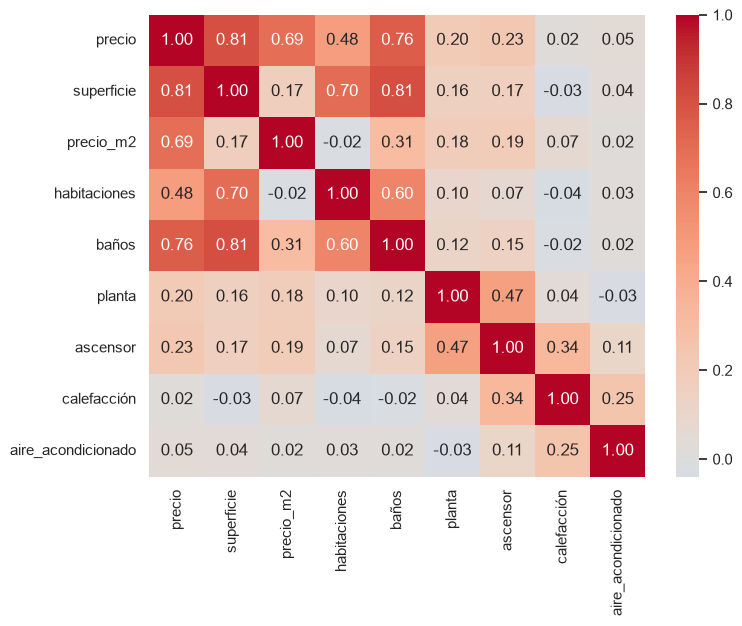

In [ ]:
numericas = ["precio", "superficie", "precio_m2", "habitaciones", "baños", "planta",
             "ascensor", "calefacción", "aire_acondicionado"]
plt.figure(figsize=(8, 6))
sns.heatmap(df_ok[numericas].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
guardar("08_correlaciones")

**Interpretación (a completar):** qué distritos son más caros, cómo cambia el precio por m² con la superficie y la planta, qué variables se relacionan entre sí.

## 8. Pregunta 1: desviación respecto a la mediana del distrito
Para las viviendas de 75 a 100 m², se calcula la mediana del precio por m² de su distrito y la desviación en % de cada vivienda respecto a ella. Solo se usan distritos con al menos 5 viviendas en el tramo.

In [ ]:
tramo_df = df_ok[df_ok["superficie"].between(TRAMO_MIN, TRAMO_MAX)].copy()
tramo_df["mediana_grupo"] = tramo_df.groupby("distrito")["precio_m2"].transform("median")
tramo_df["n_grupo"] = tramo_df.groupby("distrito")["precio_m2"].transform("count")
tramo_df = tramo_df[tramo_df["n_grupo"] >= MIN_GRUPO].copy()

resumen = tramo_df.groupby("distrito")["precio_m2"].agg(n="count", mediana="median").sort_values("mediana")
display(resumen.round(0))

,n,mediana
distrito,,
Puente de Vallecas,25,"2,368.00"
Villaverde,8,"2,385.00"
Usera,8,"2,593.00"
San Blas,18,"2,854.00"
Villa de Vallecas,10,"2,872.00"
Carabanchel,35,"3,000.00"
Vicálvaro,10,"3,397.00"
Latina,15,"3,430.00"
Moratalaz,6,"3,699.00"


count   337.00
mean      4.10
std      33.70
min     -63.60
25%     -16.50
50%       0.00
75%      18.70
max     234.70
Name: desv_pct, dtype: float64

0.05   -42.00
0.10   -31.20
0.25   -16.50
0.50     0.00
0.75    18.70
0.90    46.00
0.95    63.00
Name: desv_pct, dtype: float64

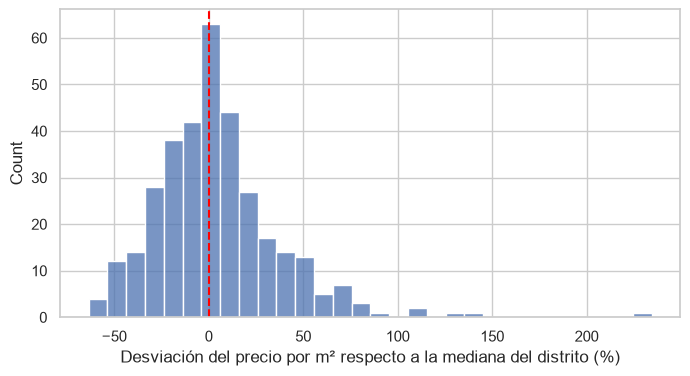

In [ ]:
tramo_df["desv_pct"] = (tramo_df["precio_m2"] / tramo_df["mediana_grupo"] - 1) * 100
display(tramo_df["desv_pct"].describe().round(1))
display(tramo_df["desv_pct"].quantile([0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]).round(1))

plt.figure(figsize=(8, 4))
sns.histplot(tramo_df["desv_pct"], bins=30)
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Desviación del precio por m² respecto a la mediana del distrito (%)")
guardar("09_desviacion_distrito")

Función de uso práctico: dado un anuncio (distrito, precio y superficie en el tramo), devuelve su desviación respecto a la mediana de su distrito.

In [ ]:
mediana_distrito = resumen["mediana"]


def desviacion(distrito, precio, superficie):
    """Desviación (%) del precio/m² de una vivienda respecto a la mediana de su distrito (tramo 75-100 m²)."""
    if not (TRAMO_MIN <= superficie <= TRAMO_MAX):
        raise ValueError("La superficie debe estar entre 75 y 100 m².")
    if distrito not in mediana_distrito.index:
        raise ValueError("Distrito sin al menos 5 viviendas en el tramo.")
    return (precio / superficie / mediana_distrito[distrito] - 1) * 100


# Ejemplo ilustrativo
print(f"{desviacion('Chamberí', 700000, 90):.1f} %")

-1.7 %


**Interpretación (a completar):** qué rango de desviación es habitual (cuartiles, percentiles 5 y 95) y a partir de qué desviación una vivienda parece cara o barata.

## 9. Pregunta 2: céntricos frente a periféricos
Mediana del precio por m² de las viviendas de 75 a 100 m² en distritos céntricos y periféricos, y diferencia entre ambas.

,n,mediana,p25,p75
zona,,,,
céntrico,88,"7,862.00","5,944.00","10,145.00"
periférico,43,"2,654.00","2,217.00","3,198.00"


Diferencia (€/m²): 5208
Sobreprecio (%): 196.2


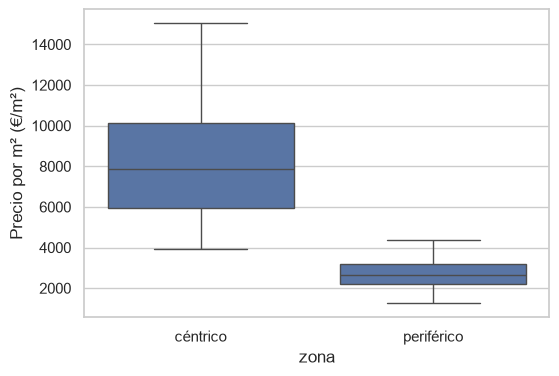

In [ ]:
q2 = df_ok[df_ok["superficie"].between(TRAMO_MIN, TRAMO_MAX)].copy()
q2["zona"] = q2["distrito"].map(
    lambda d: "céntrico" if d in CENTRICOS else ("periférico" if d in PERIFERICOS else None)
)
q2 = q2.dropna(subset=["zona"])

res_q2 = q2.groupby("zona")["precio_m2"].agg(
    n="count",
    mediana="median",
    p25=lambda s: s.quantile(0.25),
    p75=lambda s: s.quantile(0.75),
)
display(res_q2.round(0))

m = res_q2["mediana"]
print("Diferencia (€/m²):", round(m["céntrico"] - m["periférico"]))
print("Sobreprecio (%):", round((m["céntrico"] / m["periférico"] - 1) * 100, 1))

plt.figure(figsize=(6, 4))
sns.boxplot(x="zona", y="precio_m2", data=q2, showfliers=False)
plt.ylabel("Precio por m² (€/m²)")
guardar("10_centricos_perifericos")

**Interpretación (a completar):** diferencia en €/m² y en %, solape entre los rangos intercuartílicos y límites de la comparación (tamaño de los grupos, distritos elegidos).

## 10. Pregunta 3: plantas bajas frente a plantas altas
Mediana del precio por m² por tramo de superficie y grupo de planta (bajo: planta 0 o negativa; alta: planta 2 o más). Se descartan la planta 1 y las entreplantas. Después se repite controlando por distrito: se compara cada vivienda con la mediana de su distrito para que la diferencia no se deba a que los bajos estén en distritos más baratos.

In [ ]:
q3 = df_ok.copy()
q3["tramo_sup"] = q3["superficie"].apply(tramo_sup)
print(q3["grupo_planta"].value_counts())

q3 = q3[q3["grupo_planta"].isin(["bajo (0 o menos)", "alta (2 o más)"])].copy()
tabla = q3.groupby(["tramo_sup", "grupo_planta"])["precio_m2"].agg(n="count", mediana="median").round(0)
display(tabla)

grupo_planta
planta 1             1130
alta (2 o más)        379
bajo (0 o menos)       94
entreplanta (0,5)       8
Name: count, dtype: int64


n  mediana
tramo_sup      grupo_planta                  
75 a 100 m²    alta (2 o más)     74 4,828.00
               bajo (0 o menos)   22 4,559.00
menos de 75 m² alta (2 o más)     94 4,908.00
               bajo (0 o menos)   53 4,071.00
más de 100 m²  alta (2 o más)    211 6,381.00
               bajo (0 o menos)   19 3,387.00

n  mediana
tramo_sup      grupo_planta                  
75 a 100 m²    alta (2 o más)     74     2.30
               bajo (0 o menos)   22    -9.50
menos de 75 m² alta (2 o más)     94    13.20
               bajo (0 o menos)   53    -4.40
más de 100 m²  alta (2 o más)    211     6.90
               bajo (0 o menos)   19   -24.60

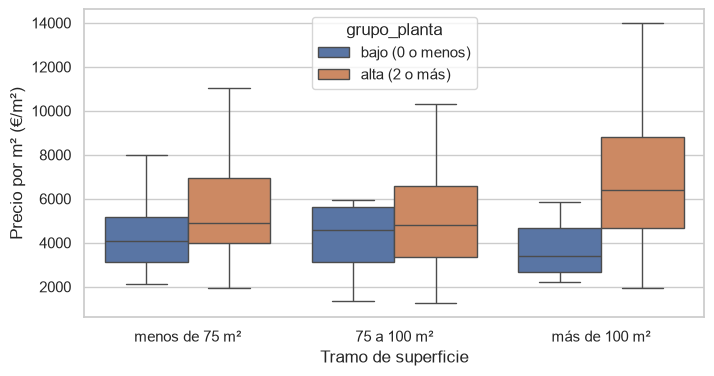

In [ ]:
med_dist = df_ok.groupby("distrito")["precio_m2"].median()
q3["rel_distrito"] = (q3["precio_m2"] / q3["distrito"].map(med_dist) - 1) * 100

display(
    q3.groupby(["tramo_sup", "grupo_planta"])["rel_distrito"]
      .agg(n="count", mediana="median")
      .round(1)
)

plt.figure(figsize=(8, 4))
sns.boxplot(x="tramo_sup", y="precio_m2", hue="grupo_planta", data=q3, showfliers=False,
            order=["menos de 75 m²", "75 a 100 m²", "más de 100 m²"])
plt.xlabel("Tramo de superficie")
plt.ylabel("Precio por m² (€/m²)")
guardar("11_bajos_altas")

**Interpretación (a completar):** descuento de los bajos por tramo, qué pasa con el tramo de 75 a 100 m² (pocos bajos, resultado frágil) y qué cambia al controlar por distrito.

## 11. Sensibilidad: sin duplicados
Se repiten las preguntas 2 y 3 quitando las filas duplicadas, para ver si los resultados dependen de ellas.

In [ ]:
df_sd = df_ok.drop_duplicates().copy()
print("Filas sin duplicados:", len(df_sd), "(antes:", len(df_ok), ")")

t = df_sd[df_sd["superficie"].between(TRAMO_MIN, TRAMO_MAX)]
cz = t[t["distrito"].isin(CENTRICOS)]["precio_m2"].median()
pz = t[t["distrito"].isin(PERIFERICOS)]["precio_m2"].median()
print("P2 sin duplicados -> céntrico:", round(cz), "periférico:", round(pz),
      "sobreprecio %:", round((cz / pz - 1) * 100, 1))

n_grupos = t.groupby("distrito")["precio_m2"].count()
print("Distritos con menos de 5 viviendas en el tramo:", list(n_grupos[n_grupos < MIN_GRUPO].index))

Filas sin duplicados: 1574 (antes: 1611 )
P2 sin duplicados -> céntrico: 7571 periférico: 2705 sobreprecio %: 180.0
Distritos con menos de 5 viviendas en el tramo: []


In [ ]:
g = df_sd.copy()
g["tramo_sup"] = g["superficie"].apply(tramo_sup)
g = g[g["grupo_planta"].isin(["bajo (0 o menos)", "alta (2 o más)"])].copy()

print("P3 sin duplicados: precio por m²")
display(g.groupby(["tramo_sup", "grupo_planta"])["precio_m2"].agg(n="count", mediana="median").round(0))

med_dist_sd = df_sd.groupby("distrito")["precio_m2"].median()
g["rel_distrito"] = (g["precio_m2"] / g["distrito"].map(med_dist_sd) - 1) * 100
print("P3 sin duplicados: relativo a la mediana del distrito (%)")
display(g.groupby(["tramo_sup", "grupo_planta"])["rel_distrito"].agg(n="count", mediana="median").round(1))

P3 sin duplicados: precio por m²


n  mediana
tramo_sup      grupo_planta                  
75 a 100 m²    alta (2 o más)     74 4,828.00
               bajo (0 o menos)   21 4,832.00
menos de 75 m² alta (2 o más)     92 4,908.00
               bajo (0 o menos)   51 4,080.00
más de 100 m²  alta (2 o más)    209 6,437.00
               bajo (0 o menos)   19 3,387.00

P3 sin duplicados: relativo a la mediana del distrito (%)


n  mediana
tramo_sup      grupo_planta                  
75 a 100 m²    alta (2 o más)     74     2.30
               bajo (0 o menos)   21    -9.40
menos de 75 m² alta (2 o más)     92    13.20
               bajo (0 o menos)   51    -4.00
más de 100 m²  alta (2 o más)    209     6.60
               bajo (0 o menos)   19   -24.60

**Interpretación (a completar):** qué resultados se mantienen sin duplicados y cuáles cambian (en la pregunta 3, tramo 75 a 100 m²).

## 12. Resumen de resultados
Cifras clave en una sola tabla para pasarlas al informe.

In [ ]:
resumen_final = pd.DataFrame({
    "Pregunta": ["P1 desviación mediana (%)", "P1 desviación rango 25-75 % (%)",
                 "P2 mediana céntrico (€/m²)", "P2 mediana periférico (€/m²)", "P2 sobreprecio (%)"],
    "Valor": [
        tramo_df["desv_pct"].median(),
        f'{tramo_df["desv_pct"].quantile(0.25):.1f} a {tramo_df["desv_pct"].quantile(0.75):.1f}',
        res_q2.loc["céntrico", "mediana"],
        res_q2.loc["periférico", "mediana"],
        (m["céntrico"] / m["periférico"] - 1) * 100,
    ],
})
display(resumen_final)

,Pregunta,Valor
0,P1 desviación mediana (%),0.00
1,P1 desviación rango 25-75 % (%),-16.5 a 18.7
2,P2 mediana céntrico (€/m²),"7,862.29"
3,P2 mediana periférico (€/m²),"2,654.32"
4,P2 sobreprecio (%),196.21
